In [1]:
import nflreadpy as nfl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
pbp = nfl.load_pbp([2026])

In [3]:
df = pbp.to_pandas()

## General Dataset Anlysis

In [4]:
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (16212, 372)


,play_id,game_id,old_game_id,home_team,away_team,season_type,week,posteam,posteam_type,defteam,...,out_of_bounds,home_opening_kickoff,qb_epa,xyac_epa,xyac_mean_yardage,xyac_median_yardage,xyac_success,xyac_fd,xpass,pass_oe
0,1.0,2026_01_ARI_LAC,2026091308,LAC,ARI,REG,1,None,None,None,...,0.0,0.0,-0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,39.0,2026_01_ARI_LAC,2026091308,LAC,ARI,REG,1,ARI,away,LAC,...,0.0,0.0,0.291195,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,62.0,2026_01_ARI_LAC,2026091308,LAC,ARI,REG,1,ARI,away,LAC,...,0.0,0.0,1.730269,0.402115,5.429666,3.0,1.0,1.000000,0.453482,54.651752
3,87.0,2026_01_ARI_LAC,2026091308,LAC,ARI,REG,1,ARI,away,LAC,...,0.0,0.0,-0.288451,NaN,NaN,NaN,NaN,NaN,0.402800,-40.280038
4,109.0,2026_01_ARI_LAC,2026091308,LAC,ARI,REG,1,ARI,away,LAC,...,0.0,0.0,-0.889568,0.361333,4.490768,2.0,1.0,0.998909,0.616770,38.322973


In [5]:
#Looking at different columns

df.columns.tolist()

['play_id',
 'game_id',
 'old_game_id',
 'home_team',
 'away_team',
 'season_type',
 'week',
 'posteam',
 'posteam_type',
 'defteam',
 'side_of_field',
 'yardline_100',
 'game_date',
 'quarter_seconds_remaining',
 'half_seconds_remaining',
 'game_seconds_remaining',
 'game_half',
 'quarter_end',
 'drive',
 'sp',
 'qtr',
 'down',
 'goal_to_go',
 'time',
 'yrdln',
 'ydstogo',
 'ydsnet',
 'desc',
 'play_type',
 'yards_gained',
 'shotgun',
 'no_huddle',
 'qb_dropback',
 'qb_kneel',
 'qb_spike',
 'qb_scramble',
 'pass_length',
 'pass_location',
 'air_yards',
 'yards_after_catch',
 'run_location',
 'run_gap',
 'field_goal_result',
 'kick_distance',
 'extra_point_result',
 'two_point_conv_result',
 'home_timeouts_remaining',
 'away_timeouts_remaining',
 'timeout',
 'timeout_team',
 'td_team',
 'td_player_name',
 'td_player_id',
 'posteam_timeouts_remaining',
 'defteam_timeouts_remaining',
 'total_home_score',
 'total_away_score',
 'posteam_score',
 'defteam_score',
 'score_differential',
 'po

In [6]:
#Finding the different play types and the amount of times they occured

df['play_type'].value_counts()

play_type
pass           6620
run            4746
no_play        1720
kickoff         956
punt            711
extra_point     424
field_goal      388
qb_kneel        143
qb_spike         33
Name: count, dtype: int64

In [7]:
#Using original datafram we found the average yards gained per play by play type

df.groupby('play_type')['yards_gained'].mean()

play_type
extra_point    0.000000
field_goal     0.000000
kickoff        0.000000
no_play        0.000000
pass           6.124320
punt           0.000000
qb_kneel      -1.188811
qb_spike       0.000000
run            4.312263
Name: yards_gained, dtype: float64

## Passing Play Analysis

In [8]:
#Creating a new dataframe of just pass plays

pass_plays = df[df['play_type'] == 'pass']

In [9]:
#Finding the average passing yards per play

str(round(pass_plays['yards_gained'].mean(), 2))

'6.12'

In [10]:
#Sorting the top 10 highest yards gained passing plays

pass_plays.sort_values(by = 'yards_gained', ascending = False).head(10)

,play_id,game_id,old_game_id,home_team,away_team,season_type,week,posteam,posteam_type,defteam,...,out_of_bounds,home_opening_kickoff,qb_epa,xyac_epa,xyac_mean_yardage,xyac_median_yardage,xyac_success,xyac_fd,xpass,pass_oe
5509,503.0,2026_03_ARI_SF,2026092709,SF,ARI,REG,3,SF,home,ARI,...,0.0,0.0,7.660430,0.994348,3.805263,2.0,0.347572,0.200109,0.968367,3.163332
5173,178.0,2026_02_SEA_ARI,2026092010,ARI,SEA,REG,2,SEA,away,ARI,...,0.0,1.0,6.907721,0.825684,10.688336,5.0,1.000000,1.000000,0.600798,39.920169
1386,531.0,2026_01_GB_MIN,2026091310,MIN,GB,REG,1,GB,away,MIN,...,0.0,1.0,7.049448,0.371987,4.684528,2.0,1.000000,1.000000,0.518829,48.117059
12613,414.0,2026_05_IND_PIT,2026101105,PIT,IND,REG,5,PIT,home,IND,...,0.0,1.0,5.702825,0.782944,6.872151,6.0,0.578250,0.227173,0.511861,48.813862
4341,3614.0,2026_02_MIA_SF,2026092012,SF,MIA,REG,2,MIA,away,SF,...,0.0,0.0,7.010916,1.272485,12.779172,5.0,1.000000,1.000000,0.940648,5.935156
5807,3290.0,2026_03_ATL_GB,2026092400,GB,ATL,REG,3,ATL,away,GB,...,1.0,0.0,5.162955,0.612609,8.356286,4.0,1.000000,1.000000,0.724288,27.571213
2617,801.0,2026_01_WAS_PHI,2026091311,PHI,WAS,REG,1,PHI,home,WAS,...,0.0,0.0,4.174296,1.081391,12.300362,7.0,1.000000,1.000000,0.463226,53.677404
4720,1147.0,2026_02_NYG_LA,2026092100,LA,NYG,REG,2,LA,home,NYG,...,0.0,0.0,5.417247,0.687332,9.222065,4.0,1.000000,1.000000,0.976204,2.379584
13772,2555.0,2026_05_TB_DAL,2026100800,DAL,TB,REG,5,TB,away,DAL,...,1.0,1.0,5.435248,0.569475,7.854295,4.0,1.000000,1.000000,0.805184,19.481635
5115,2869.0,2026_02_PIT_NE,2026092004,NE,PIT,REG,2,NE,home,PIT,...,1.0,0.0,4.001853,0.932838,12.621468,5.0,1.000000,1.000000,0.366695,63.330472


In [11]:
#Total number of pass plays, incomplete and completed

len(pass_plays)

6620

In [12]:
#Only counting completed passes

len(pass_plays[pass_plays['complete_pass'] == 1])

3951

In [13]:
#Finding the amount of passing plays that resulted in a first down

len(pass_plays[pass_plays['first_down'] == 1])

2092

In [14]:
#Finding the total passing attempts/completed passes and getting the overall completion %

pass_attempts = len(pass_plays['pass_attempt'])
completed_passes = len(pass_plays[pass_plays['complete_pass'] == 1])

completion_percentage = (completed_passes / pass_attempts) * 100

print("The overall completion percentage up until the current week in the NFL is:", round(completion_percentage, 2))

The overall completion percentage up until the current week in the NFL is: 59.68


In [15]:
#Finding average yards per completed pass

round(pass_plays[pass_plays['complete_pass'] == 1]['yards_gained'].mean(), 2)

np.float64(10.94)

## Team Analysis

In [16]:
#Finding unique team abbreviations

df['posteam'].unique()

array([None, 'ARI', 'LAC', 'PIT', 'ATL', 'IND', 'BAL', 'BUF', 'HOU',
       'CHI', 'CAR', 'CLE', 'JAX', 'DAL', 'NYG', 'DEN', 'KC', 'MIN', 'GB',
       'MIA', 'LV', 'SEA', 'NE', 'DET', 'NO', 'NYJ', 'TEN', 'LA', 'SF',
       'TB', 'CIN', 'WAS', 'PHI'], dtype=object)

In [17]:
#Finding average yards gained by team

round(df.groupby('posteam')['yards_gained'].mean().sort_values(ascending = False),2)

posteam
KC     5.28
SF     4.98
BUF    4.90
LA     4.61
NE     4.59
DET    4.55
ATL    4.50
CAR    4.50
BAL    4.48
JAX    4.38
CIN    4.27
CHI    4.27
DAL    4.27
HOU    4.26
GB     4.11
LV     4.06
SEA    4.05
MIA    3.85
NYG    3.84
WAS    3.84
PIT    3.77
NYJ    3.75
IND    3.71
NO     3.64
ARI    3.54
TB     3.52
MIN    3.51
LAC    3.48
TEN    3.39
CLE    3.37
PHI    3.33
DEN    3.26
Name: yards_gained, dtype: float64

In [18]:
#Filtering to only show Kansas City

df[df['posteam'] == 'KC'].head()

,play_id,game_id,old_game_id,home_team,away_team,season_type,week,posteam,posteam_type,defteam,...,out_of_bounds,home_opening_kickoff,qb_epa,xyac_epa,xyac_mean_yardage,xyac_median_yardage,xyac_success,xyac_fd,xpass,pass_oe
1209,126.0,2026_01_DEN_KC,2026091400,KC,DEN,REG,1,KC,home,DEN,...,0.0,0.0,-0.449889,NaN,NaN,NaN,NaN,NaN,0.436777,-43.677735
1210,148.0,2026_01_DEN_KC,2026091400,KC,DEN,REG,1,KC,home,DEN,...,0.0,0.0,-0.047746,NaN,NaN,NaN,NaN,NaN,0.678747,-67.874742
1211,170.0,2026_01_DEN_KC,2026091400,KC,DEN,REG,1,KC,home,DEN,...,0.0,0.0,-1.674052,NaN,NaN,NaN,NaN,NaN,0.847737,-84.773660
1212,192.0,2026_01_DEN_KC,2026091400,KC,DEN,REG,1,KC,home,DEN,...,0.0,0.0,2.773584,NaN,NaN,NaN,NaN,NaN,0.777337,-77.733690
1213,220.0,2026_01_DEN_KC,2026091400,KC,DEN,REG,1,KC,home,DEN,...,0.0,0.0,-0.509119,0.243511,3.162037,1.0,0.998908,0.471895,0.453168,54.683167


In [19]:
#Finding just Kansas City's average passing yards gained

kc_passing = df[(df['posteam'] == 'KC') & (df['play_type'] == 'pass')]

print("Kansas City's average passing yards gained is:", round(kc_passing['yards_gained'].mean(), 2))

Kansas City's average passing yards gained is: 7.7


In [20]:
#Finding which teams attmepted the most passes sorting from highest to lowest

df.groupby('posteam')['pass_attempt'].sum().sort_values(ascending = False)

posteam
LA     264.0
DAL    256.0
PIT    255.0
NO     249.0
ARI    247.0
GB     240.0
NYG    234.0
HOU    234.0
IND    233.0
LV     232.0
CHI    223.0
TB     216.0
PHI    216.0
CAR    215.0
SEA    215.0
DET    202.0
LAC    202.0
NE     201.0
CLE    200.0
DEN    199.0
CIN    198.0
NYJ    198.0
JAX    195.0
TEN    188.0
BUF    186.0
ATL    186.0
BAL    183.0
WAS    174.0
KC     165.0
MIN    156.0
SF     146.0
MIA    145.0
Name: pass_attempt, dtype: float64

In [21]:
pass_attempts = df.groupby('posteam')['pass_attempt'].sum()

In [22]:
#Finding the completion percentage for each team and ranking them from highest to lowest

pass_attempts = df.groupby('posteam')['pass_attempt'].sum()
completed_pass = df.groupby('posteam')['complete_pass'].sum()

total_team_comp_percentage = round((completed_pass / pass_attempts) * 100, 2).sort_values(ascending = False)

total_team_comp_percentage

posteam
CIN    68.18
SF     67.12
BAL    65.03
CHI    64.13
DAL    63.67
KC     63.64
ARI    63.56
DET    63.37
LA     62.88
NYJ    61.62
JAX    61.54
NO     61.45
BUF    61.29
HOU    61.11
LV     60.78
NE     60.20
MIN    58.97
SEA    58.60
TEN    57.98
DEN    57.29
CAR    56.28
GB     56.25
PIT    56.08
TB     56.02
CLE    56.00
IND    55.79
ATL    55.38
WAS    54.60
NYG    54.27
PHI    53.24
LAC    52.97
MIA    50.34
dtype: float64

In [23]:
#Finding the top 10 teams by total passing yards

df[df['play_type'] == 'pass'].groupby('posteam')['yards_gained'].sum().sort_values(ascending = False).head(10)

posteam
LA     1732.0
HOU    1621.0
GB     1618.0
DAL    1605.0
LV     1583.0
CAR    1478.0
NE     1463.0
BUF    1435.0
JAX    1409.0
DET    1398.0
Name: yards_gained, dtype: float64

In [24]:
#Finding the top 10 teams by average yards gained per pass play

pass_plays = df[df['play_type'] == 'pass']

passing_yards = pass_plays.groupby('posteam')['yards_gained'].sum()

passing_attempts = df.groupby('posteam')['pass_attempt'].sum()

yards_per_attempt = round(passing_yards / passing_attempts, 2).sort_values(ascending = False)

yards_per_attempt.head(10)

posteam
SF     8.11
BUF    7.72
KC     7.70
NE     7.28
JAX    7.23
BAL    7.09
HOU    6.93
DET    6.92
CAR    6.87
LV     6.82
dtype: float64

In [25]:
#Finding total number of passing touchdowns by team

df.groupby('posteam')['pass_touchdown'].sum().sort_values(ascending = False)

posteam
LV     14.0
JAX    14.0
SF     13.0
PIT    12.0
DET    12.0
NO     12.0
LA     11.0
SEA    11.0
CAR    11.0
CIN    11.0
NYG    11.0
GB     11.0
NE     11.0
DAL    10.0
PHI     9.0
ARI     9.0
KC      9.0
HOU     9.0
BUF     9.0
BAL     9.0
WAS     8.0
ATL     7.0
NYJ     7.0
CLE     7.0
DEN     6.0
LAC     5.0
MIN     5.0
CHI     5.0
TB      5.0
IND     4.0
TEN     4.0
MIA     2.0
Name: pass_touchdown, dtype: float64

In [26]:
#Finding total interceptions by team

df.groupby('posteam')['interception'].sum().sort_values(ascending = False)

posteam
LAC    8.0
TB     7.0
SEA    7.0
NE     7.0
ATL    7.0
ARI    6.0
IND    6.0
NYG    6.0
LA     6.0
DAL    5.0
LV     5.0
CHI    5.0
NO     5.0
PIT    5.0
PHI    4.0
GB     4.0
TEN    4.0
JAX    4.0
MIA    4.0
BUF    4.0
DEN    3.0
KC     3.0
CIN    3.0
SF     2.0
MIN    2.0
CAR    2.0
CLE    2.0
NYJ    1.0
BAL    1.0
HOU    1.0
WAS    1.0
DET    0.0
Name: interception, dtype: float64

## QB Analysis

In [27]:
#Finding the top 10 total passing yards for each QB

pass_plays = df[df['play_type'] == 'pass']

pass_plays.groupby('passer_player_name')['yards_gained'].sum().sort_values(ascending = False).head(10)

passer_player_name
M.Stafford    1719.0
C.Stroud      1621.0
J.Love        1618.0
D.Prescott    1605.0
K.Cousins     1535.0
B.Young       1478.0
J.Allen       1435.0
D.Maye        1417.0
T.Lawrence    1409.0
J.Goff        1398.0
Name: yards_gained, dtype: float64

In [28]:
#Calculating QB Completion Percentage with more then 10 total passing attempts

pass_plays = df[df['play_type'] == 'pass']

pass_completed_qb = pass_plays.groupby('passer_player_name')['complete_pass'].sum()

pass_attempt_qb = pass_plays.groupby('passer_player_name')['pass_attempt'].sum()
pass_attempt_qb_greater_10 = pass_attempt_qb[pass_attempt_qb > 10]

completion_percent = round((pass_completed_qb / pass_attempt_qb_greater_10) * 100, 2).sort_values(ascending = False).head(10)

completion_percent

passer_player_name
J.Dart        72.22
D.Lock        70.00
J.Burrow      68.18
B.Purdy       67.59
L.Jackson     67.33
C.Williams    66.00
T.Huntley     64.56
J.Brissett    63.93
D.Prescott    63.67
C.Keenum      63.64
dtype: float64

In [29]:
#Calculating top 10 QB interception leaders

df.groupby('passer_player_name')['interception'].sum().sort_values(ascending = False).head(10)

passer_player_name
J.Herbert     8.0
S.Darnold     7.0
D.Maye        7.0
J.Brissett    6.0
M.Stafford    6.0
D.Jones       6.0
D.Prescott    5.0
T.Shough      5.0
J.Winston     5.0
K.Cousins     5.0
Name: interception, dtype: float64

In [30]:
#Calculating top 10 QB yards per attempt (minimum 100 attempts)

pass_plays = df[df['play_type'] == 'pass']

pass_attempt_qb = pass_plays.groupby('passer_player_name')['pass_attempt'].sum()
pass_attempt_qb_greater_100 = pass_attempt_qb[pass_attempt_qb > 100]

pass_yards_gained_qb = pass_plays.groupby('passer_player_name')['yards_gained'].sum()

total_pass_per_attempt_qb = round((pass_yards_gained_qb / pass_attempt_qb_greater_100), 2).sort_values(ascending = False).head(10)

total_pass_per_attempt_qb

passer_player_name
L.Jackson     8.94
B.Purdy       8.17
J.Allen       7.72
P.Mahomes     7.70
M.Penix       7.33
D.Maye        7.27
T.Lawrence    7.26
C.Stroud      7.08
K.Cousins     6.95
B.Young       6.94
dtype: float64

## Creating QB Stats Table

In [31]:
#Creating a QB stats table

pass_plays = df[df['play_type'] == 'pass']

qb_stats = pass_plays.groupby('passer_player_name')['pass_attempt'].sum().reset_index()

qb_stats.head()

,passer_player_name,pass_attempt
0,A.Dalton,1.0
1,A.Kaliakmanis,34.0
2,A.Rodgers,250.0
3,A.Williams,1.0
4,B.Mayfield,109.0


In [32]:
#Creating a new column of passing yards to add in, using map function to map the qb in the main table with the formula output

qb_stats['passing_yards'] = qb_stats['passer_player_name'].map(pass_plays.groupby('passer_player_name')['yards_gained'].sum())

qb_stats.head()

,passer_player_name,pass_attempt,passing_yards
0,A.Dalton,1.0,0.0
1,A.Kaliakmanis,34.0,177.0
2,A.Rodgers,250.0,1328.0
3,A.Williams,1.0,0.0
4,B.Mayfield,109.0,555.0


In [33]:
#Adding in interceptions thrown by each QB

qb_stats['interceptions'] = qb_stats['passer_player_name'].map(pass_plays.groupby('passer_player_name')['interception'].sum())

qb_stats.head()

,passer_player_name,pass_attempt,passing_yards,interceptions
0,A.Dalton,1.0,0.0,1.0
1,A.Kaliakmanis,34.0,177.0,1.0
2,A.Rodgers,250.0,1328.0,5.0
3,A.Williams,1.0,0.0,0.0
4,B.Mayfield,109.0,555.0,2.0


In [34]:
#Adding completion percentage into the table

qb_stats['completions'] = qb_stats['passer_player_name'].map(pass_plays.groupby('passer_player_name')['complete_pass'].sum())

qb_stats['completion_pct'] = round((qb_stats['completions'] / qb_stats['pass_attempt']) * 100, 2)

qb_stats.head()

,passer_player_name,pass_attempt,passing_yards,interceptions,completions,completion_pct
0,A.Dalton,1.0,0.0,1.0,0.0,0.00
1,A.Kaliakmanis,34.0,177.0,1.0,15.0,44.12
2,A.Rodgers,250.0,1328.0,5.0,143.0,57.20
3,A.Williams,1.0,0.0,0.0,0.0,0.00
4,B.Mayfield,109.0,555.0,2.0,61.0,55.96


In [35]:
#Adding yards per attempt into the table

qb_stats['yards_per_attempt'] = round(qb_stats['passing_yards'] / qb_stats['pass_attempt'], 2)

qb_stats.head()

,passer_player_name,pass_attempt,passing_yards,interceptions,completions,completion_pct,yards_per_attempt
0,A.Dalton,1.0,0.0,1.0,0.0,0.00,0.00
1,A.Kaliakmanis,34.0,177.0,1.0,15.0,44.12,5.21
2,A.Rodgers,250.0,1328.0,5.0,143.0,57.20,5.31
3,A.Williams,1.0,0.0,0.0,0.0,0.00,0.00
4,B.Mayfield,109.0,555.0,2.0,61.0,55.96,5.09


In [36]:
#Creating new column of passing touchdowns

qb_stats['passing_tds'] = qb_stats['passer_player_name'].map(pass_plays.groupby('passer_player_name')['pass_touchdown'].sum())

qb_stats.head()

,passer_player_name,pass_attempt,passing_yards,interceptions,completions,completion_pct,yards_per_attempt,passing_tds
0,A.Dalton,1.0,0.0,1.0,0.0,0.00,0.00,0.0
1,A.Kaliakmanis,34.0,177.0,1.0,15.0,44.12,5.21,1.0
2,A.Rodgers,250.0,1328.0,5.0,143.0,57.20,5.31,12.0
3,A.Williams,1.0,0.0,0.0,0.0,0.00,0.00,0.0
4,B.Mayfield,109.0,555.0,2.0,61.0,55.96,5.09,2.0


In [37]:
#Creating TD percentage, how likely a QB is to throw a TD based on passing attempts (NOT completed passes)

qb_stats['td_percentage'] = round((qb_stats['passing_tds'] / qb_stats['pass_attempt']) * 100, 2)

qb_stats.head()

,passer_player_name,pass_attempt,passing_yards,interceptions,completions,completion_pct,yards_per_attempt,passing_tds,td_percentage
0,A.Dalton,1.0,0.0,1.0,0.0,0.00,0.00,0.0,0.00
1,A.Kaliakmanis,34.0,177.0,1.0,15.0,44.12,5.21,1.0,2.94
2,A.Rodgers,250.0,1328.0,5.0,143.0,57.20,5.31,12.0,4.80
3,A.Williams,1.0,0.0,0.0,0.0,0.00,0.00,0.0,0.00
4,B.Mayfield,109.0,555.0,2.0,61.0,55.96,5.09,2.0,1.83


In [38]:
#Creating interception percentage based on passing attempts

qb_stats['int_percentage'] = round((qb_stats['interceptions'] / qb_stats['pass_attempt']) * 100, 2)

qb_stats.head()

,passer_player_name,pass_attempt,passing_yards,interceptions,completions,completion_pct,yards_per_attempt,passing_tds,td_percentage,int_percentage
0,A.Dalton,1.0,0.0,1.0,0.0,0.00,0.00,0.0,0.00,100.00
1,A.Kaliakmanis,34.0,177.0,1.0,15.0,44.12,5.21,1.0,2.94,2.94
2,A.Rodgers,250.0,1328.0,5.0,143.0,57.20,5.31,12.0,4.80,2.00
3,A.Williams,1.0,0.0,0.0,0.0,0.00,0.00,0.0,0.00,0.00
4,B.Mayfield,109.0,555.0,2.0,61.0,55.96,5.09,2.0,1.83,1.83


In [39]:
#Sorting QB stats to see who has the most passing ayrds

qb_stats.sort_values(by = 'passing_yards', ascending = False).head(10)

,passer_player_name,pass_attempt,passing_yards,interceptions,completions,completion_pct,yards_per_attempt,passing_tds,td_percentage,int_percentage
45,M.Stafford,258.0,1719.0,6.0,164.0,63.57,6.66,11.0,4.26,2.33
11,C.Stroud,229.0,1621.0,1.0,143.0,62.45,7.08,9.0,3.93,0.44
32,J.Love,240.0,1618.0,4.0,135.0,56.25,6.74,11.0,4.58,1.67
19,D.Prescott,256.0,1605.0,5.0,163.0,63.67,6.27,10.0,3.91,1.95
37,K.Cousins,221.0,1535.0,5.0,135.0,61.09,6.95,14.0,6.33,2.26
7,B.Young,213.0,1478.0,2.0,121.0,56.81,6.94,11.0,5.16,0.94
24,J.Allen,186.0,1435.0,4.0,114.0,61.29,7.72,9.0,4.84,2.15
18,D.Maye,195.0,1417.0,7.0,117.0,60.00,7.27,11.0,5.64,3.59
56,T.Lawrence,194.0,1409.0,4.0,120.0,61.86,7.26,14.0,7.22,2.06
29,J.Goff,202.0,1398.0,0.0,128.0,63.37,6.92,12.0,5.94,0.00


## Visualizing QB Data

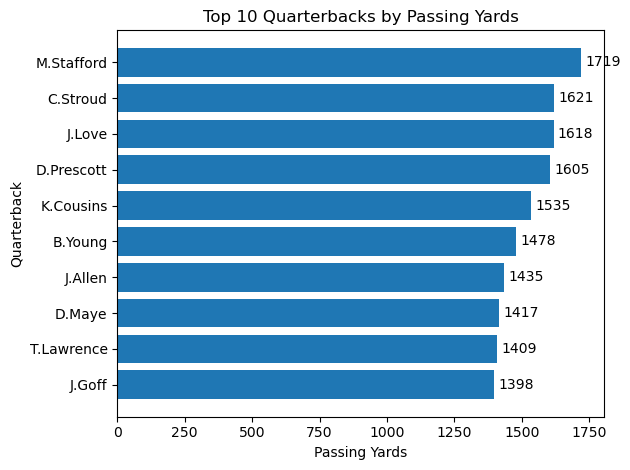

In [40]:
#Visualizing top 10 QBs by passing yards bar chart

top_10_qbs = qb_stats.sort_values(by = 'passing_yards', ascending = False).head(10)

bars = plt.barh(top_10_qbs['passer_player_name'],
         top_10_qbs['passing_yards'],
        color = 'tab:blue')

plt.title('Top 10 Quarterbacks by Passing Yards')
plt.xlabel('Passing Yards')
plt.ylabel('Quarterback')
plt.bar_label(bars, padding = 3)

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [41]:
#Want to first filter out and only show QBs with 150+ passing yards minimum

qb_yards_filtered = qb_stats[qb_stats['passing_yards'] > 150]

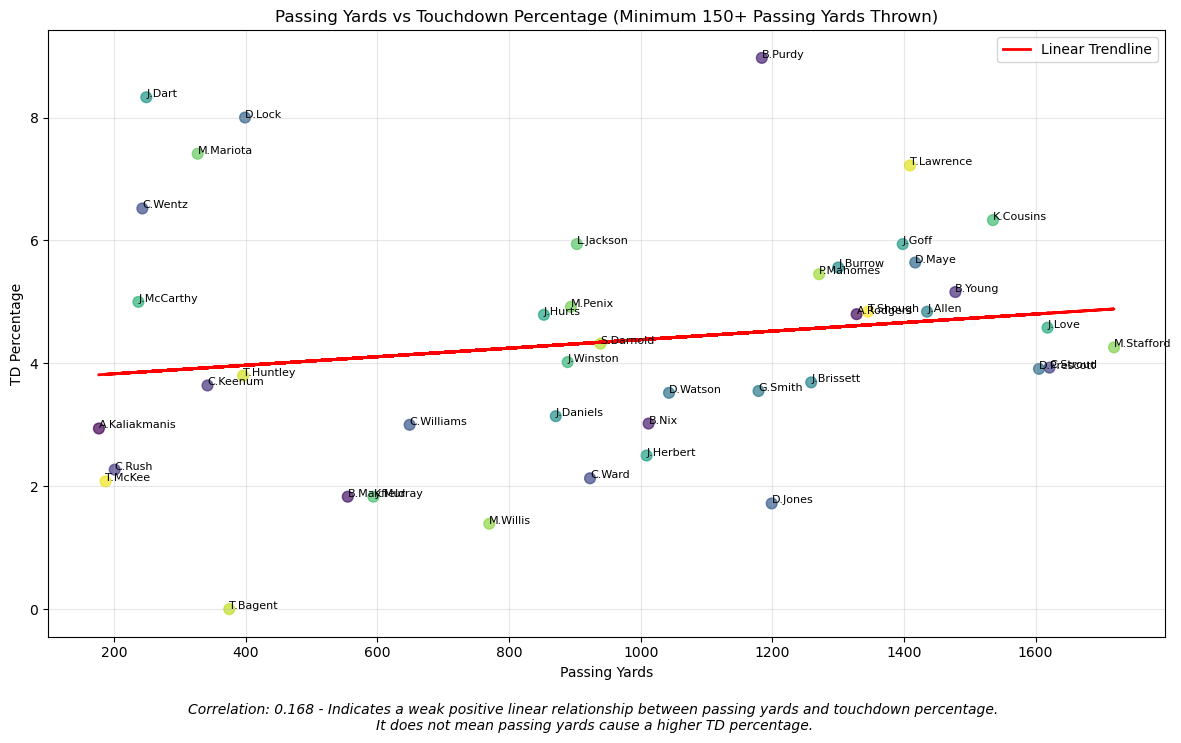

In [43]:
#Creating scatter plot to compare passing yards against touchdown percentage

#Calculating the correlation

qb_corr = round(qb_yards_filtered['passing_yards'].corr(qb_yards_filtered['td_percentage']), 3)

#Creating Trendline
x = qb_yards_filtered['passing_yards']
y = qb_yards_filtered['td_percentage']
coefficients = np.polyfit(x, y, 1)
trendline = np.poly1d(coefficients)

#Scatter Plot
plt.figure(figsize = (12, 7))
plt.scatter(qb_yards_filtered['passing_yards'], qb_yards_filtered['td_percentage'], c = range(len(qb_yards_filtered)), cmap = 'viridis', s = 60, alpha = 0.7)

#This creates the QB annotation for each circle
for index, row in qb_yards_filtered.iterrows():
    plt.annotate(
        row['passer_player_name'],
        (row['passing_yards'], row['td_percentage']), fontsize = 8)

#General Scatterplot descriptions
plt.title('Passing Yards vs Touchdown Percentage (Minimum 150+ Passing Yards Thrown)')
plt.xlabel('Passing Yards')
plt.ylabel('TD Percentage')

#This creates the trendline
plt.plot(x, trendline(x), color = 'red', linewidth = 2, label = 'Linear Trendline')

#Adding an annocation at the bottom to explain the correlation
plt.figtext(
    0.5, -0.05,
    f'Correlation: {qb_corr:.3f} - Indicates a weak positive linear relationship between passing yards and touchdown percentage. \nIt does not mean passing yards cause a higher TD percentage.',
    ha = 'center',
    fontsize = 10,
    style = 'italic')

plt.tight_layout()
plt.grid(True, alpha = 0.3)
plt.legend()
plt.show()

## QB Touchdown Percentage Analysis

In [53]:
#Creating a new Dataframe with the respected columns below and then sorting the highest td_percentages only showing top 10

top_10_td_pct = qb_yards_filtered[['passer_player_name', 'pass_attempt', 'passing_tds', 'td_percentage']]

top_10_td_pct = top_10_td_pct.sort_values(by = 'td_percentage', ascending = False).head(10)
top_10_td_pct

,passer_player_name,pass_attempt,passing_tds,td_percentage
6,B.Purdy,145.0,13.0,8.97
28,J.Dart,36.0,3.0,8.33
17,D.Lock,50.0,4.0,8.00
42,M.Mariota,54.0,4.0,7.41
56,T.Lawrence,194.0,14.0,7.22
13,C.Wentz,46.0,3.0,6.52
37,K.Cousins,221.0,14.0,6.33
29,J.Goff,202.0,12.0,5.94
41,L.Jackson,101.0,6.0,5.94
18,D.Maye,195.0,11.0,5.64
